# ML Classifier Experiment: Random Forest and Gradient Boosting

**Author:** Trang
**Phase:** II – Identity Resolution (matcher comparison)
**Data:** `gs_pair_train_val.csv` (2,973 pairs) for training and tuning; `gs_pair_test.csv` (525 pairs) for the final evaluation only.

This notebook follows the setup of `ml_classifier_experiment.ipynb` (SVM + Logistic Regression) and uses the same features, CV and metric, so the results can be compared directly.

| Design choice | Setting |
|---|---|
| Classifiers | `RandomForestClassifier`, `GradientBoostingClassifier` |
| Features | The 6 similarity features of the SVM/LR notebook, unchanged, so that all four ML classifiers are compared on identical inputs |
| HPO | `RandomizedSearchCV`, 40 settings per model, same CV as SVM/LR: `StratifiedKFold(5, shuffle=True, random_state=42)`, scoring `f1_macro` |
| Threshold | Default 0.50 and a threshold chosen on out-of-fold CV probabilities (train/val only), same rule as the DistilBERT notebook |
| Metric | **Macro F1** = mean of match F1 and non-match F1 (`average='macro'`), the team-wide definition. Reported overall, by difficulty and by source pair. We also report the **source-pair-balanced Macro F1** (mean of the three source-pair Macro F1 values), so each pair type contributes equally. |

The `hard` column is **not** used as a feature. It only records the sampling pool of the gold standard and does not exist for blocking candidates. It is used only to split the evaluation.

In [1]:
import sys
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import randint, uniform

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, classification_report,
)

project_root = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / 'data/5_golden_standard_pair').is_dir()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.identity_resolution.ml_features import (
    extract_features, FEATURE_NAMES,
)

train_path = project_root / 'data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_train_val.csv'
test_path  = project_root / 'data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_test.csv'
eval_dir   = project_root / 'data/6_evaluation'
fig_dir    = project_root / 'notebooks/ml_tree_classifier_experiment'

RANDOM_STATE = 42
N_ITER = 40          # random-search settings per model
N_JOBS = -1

## 1. Load the gold standard

In [2]:
train = pd.read_csv(train_path)
test  = pd.read_csv(test_path)

required = ['id1', 'id2', 'source_pair', 'hard', 'match',
            'brandName1', 'brandName2', 'activeSubstances1', 'activeSubstances2',
            'licenceHolder1', 'licenceHolder2']
for df, name in [(train, 'train'), (test, 'test')]:
    assert set(required).issubset(df.columns), f'{name} missing columns'
    assert df['match'].isin([0, 1]).all()
assert not set(train['pair_id']) & set(test['pair_id']), 'train/test overlap'

print(f'Train: {len(train)} pairs  |  Test: {len(test)} pairs')
print('\nTrain class distribution:')
display(train.groupby(['source_pair', 'match']).size().unstack(fill_value=0))
print('\nTest class distribution:')
display(test.groupby(['source_pair', 'match']).size().unstack(fill_value=0))

Train: 2973 pairs  |  Test: 525 pairs

Train class distribution:


match,0,1
source_pair,,
dpd_ema,498,352
dpd_fda,442,211
ema_fda,982,488



Test class distribution:


match,0,1
source_pair,,
dpd_ema,87,63
dpd_fda,79,37
ema_fda,173,86


## 2. Feature extraction

The six features of the SVM/LR notebook, moved into `src/identity_resolution/ml_features.py` so the same code can later score the blocking candidates:

| Feature | Meaning |
|---|---|
| `brand_sim` | SequenceMatcher ratio of the normalised brand names |
| `substance_sim` | SequenceMatcher ratio of the normalised active-substance strings |
| `substance_token_jaccard` | Jaccard overlap of substance tokens after removing salt forms |
| `holder_sim` | Overlap coefficient of licence-holder tokens after removing legal suffixes |
| `holder_missing` | 1 if either licence holder is missing |
| `substance_count_diff` | Absolute difference in the number of active substances |

Tree ensembles need no feature scaling.

In [3]:
t0 = time.time()
X_train, X_test = extract_features(train), extract_features(test)
y_train, y_test = train['match'].values, test['match'].values
print(f'Feature extraction: {time.time() - t0:.1f}s  |  {X_train.shape[1]} features')

# Mean feature value per label on the training data (sanity check)
display(X_train.groupby(train['match']).mean().T.rename(columns={0: 'non-match', 1: 'match'}).round(3))

Feature extraction: 0.4s  |  6 features


match,non-match,match
brand_sim,0.486,0.946
substance_sim,0.519,0.897
substance_token_jaccard,0.395,0.899
holder_sim,0.033,0.588
holder_missing,0.067,0.031
substance_count_diff,0.650,0.064


## 3. Hyperparameter optimisation with 5-fold cross-validation

Same CV object and scoring as the SVM/LR notebook. The test set is not touched here.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_space = {
    'n_estimators':     randint(100, 600),
    'max_depth':        [None, 6, 10, 16, 24],
    'min_samples_leaf': randint(1, 8),
    'max_features':     ['sqrt', 'log2', 0.5, 0.8],
    'class_weight':     [None, 'balanced'],
}
gb_space = {
    'n_estimators':     randint(100, 600),
    'learning_rate':    uniform(0.02, 0.18),
    'max_depth':        randint(2, 6),
    'subsample':        uniform(0.6, 0.4),
    'min_samples_leaf': randint(1, 10),
}

model_specs = {
    'Random Forest':     (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), rf_space),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE), gb_space),
}

searches, hpo_rows = {}, []
for model_name, (estimator, space) in model_specs.items():
    if True:
        key = model_name
        Xtr = X_train
        t0 = time.time()
        search = RandomizedSearchCV(
            estimator, space, n_iter=N_ITER, scoring='f1_macro',
            cv=cv, n_jobs=N_JOBS, random_state=RANDOM_STATE,
        )
        search.fit(Xtr, y_train)
        searches[key] = search
        best_idx = search.best_index_
        hpo_rows.append({
            'config': key,
            'cv_macro_f1': search.best_score_,
            'cv_std': search.cv_results_['std_test_score'][best_idx],
            'search_time_s': time.time() - t0,
            'best_params': {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                            for k, v in search.best_params_.items()},
        })
        print(f'{key:20s} CV macro F1 = {search.best_score_:.4f} '
              f'(± {search.cv_results_["std_test_score"][best_idx]:.4f})  [{time.time() - t0:.0f}s]')
        print(f'    best params: {hpo_rows[-1]["best_params"]}')

hpo_df = pd.DataFrame(hpo_rows).set_index('config')
display(hpo_df[['cv_macro_f1', 'cv_std', 'search_time_s']].round(4))

Random Forest        CV macro F1 = 0.9023 (± 0.0101)  [74s]
    best params: {'class_weight': 'balanced', 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 287}


Gradient Boosting    CV macro F1 = 0.8964 (± 0.0093)  [74s]
    best params: {'learning_rate': 0.0333, 'max_depth': 4, 'min_samples_leaf': 9, 'n_estimators': 127, 'subsample': 0.9452}


,cv_macro_f1,cv_std,search_time_s
config,,,
Random Forest,0.9023,0.0101,73.8388
Gradient Boosting,0.8964,0.0093,73.7126


## 4. Decision threshold on out-of-fold probabilities

For each tuned configuration, out-of-fold probabilities on train/val are computed with the same 5 folds. The threshold is swept from 0.10 to 0.90 (step 0.01) and the one with the highest Macro F1 is kept; ties go to the value closest to 0.50, then the smaller one (same rule as `PLM_DistilBERT/02_tune_threshold.ipynb`).

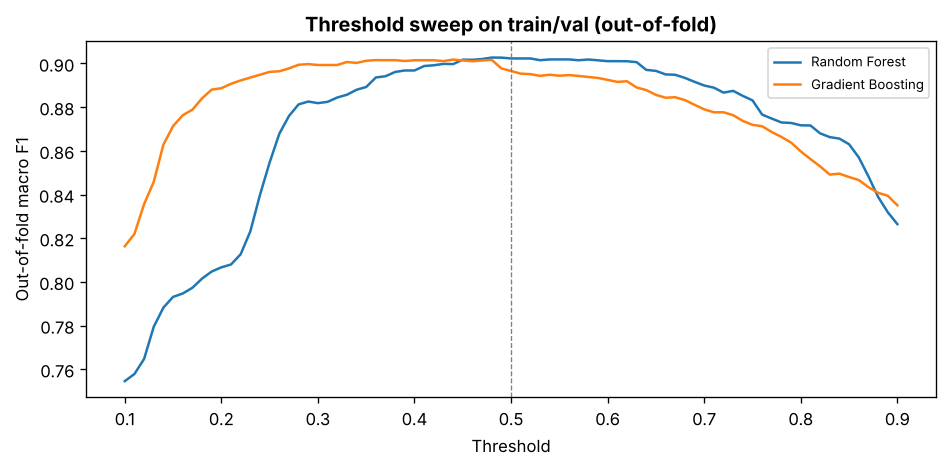

,oof_macro_f1@0.50,tuned_threshold,oof_macro_f1@tuned
config,,,
Random Forest,0.9023,0.48,0.9027
Gradient Boosting,0.8966,0.44,0.9018


In [5]:
thresholds = np.round(np.arange(0.10, 0.901, 0.01), 2)
tuned_thr, oof_rows = {}, []
fig, ax = plt.subplots(figsize=(8, 4), dpi=120)

for key, search in searches.items():
    Xtr = X_train
    oof = cross_val_predict(clone(search.best_estimator_), Xtr, y_train,
                            cv=cv, method='predict_proba', n_jobs=N_JOBS)[:, 1]
    scores = np.array([f1_score(y_train, (oof >= t).astype(int), average='macro') for t in thresholds])
    best = scores.max()
    cands = thresholds[np.isclose(scores, best)]
    thr = float(sorted(cands, key=lambda t: (abs(t - 0.5), t))[0])
    tuned_thr[key] = thr
    oof_rows.append({'config': key, 'oof_macro_f1@0.50': f1_score(y_train, (oof >= 0.5).astype(int), average='macro'),
                     'tuned_threshold': thr, 'oof_macro_f1@tuned': best})
    ax.plot(thresholds, scores, label=key)

ax.axvline(0.5, color='grey', lw=0.8, ls='--')
ax.set_xlabel('Threshold'); ax.set_ylabel('Out-of-fold macro F1')
ax.set_title('Threshold sweep on train/val (out-of-fold)', fontweight='bold')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(fig_dir / 'ml_tree_classifier_threshold_tuning.png', bbox_inches='tight')
plt.show()

oof_df = pd.DataFrame(oof_rows).set_index('config')
display(oof_df.round(4))

## 5. Reference matchers on the same test set

So everything in the comparison table is computed with the same code:
- **Exact-match baseline**: normalised brand equal and active-substance set equal (same rule as `compute_baseline_match` in the LLM matcher).
- **SVM / Logistic Regression**: refit on the same features with the best hyperparameters reported in `ml_classifier_experiment.ipynb` (SVM `C=100, gamma=0.1`; LR `C=0.1`, liblinear). The test scores below should reproduce that notebook.
- **DistilBERT** (validation-tuned threshold) and **Zero-shot LLM**: loaded from their saved prediction files.

In [6]:
import re

def _norm(s):
    return ' '.join(re.sub(r'[^\w\s]', ' ', str(s).upper()).split()) if pd.notna(s) else ''

def _subs(s):
    return {_norm(p) for p in str(s).split(';') if p.strip()} if pd.notna(s) else set()

def baseline_match(row):
    b1, b2 = _norm(row['brandName1']), _norm(row['brandName2'])
    s1, s2 = _subs(row['activeSubstances1']), _subs(row['activeSubstances2'])
    return int(b1 == b2 and b1 != '' and s1 == s2 and len(s1) > 0)

ref_preds = {'Exact-match baseline': test.apply(baseline_match, axis=1).values}

svm = Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', C=100, gamma=0.1, random_state=RANDOM_STATE))])
lr  = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(C=0.1, solver='liblinear', max_iter=1000, random_state=RANDOM_STATE))])
ref_preds['SVM'] = svm.fit(X_train, y_train).predict(X_test)
ref_preds['Logistic Regression'] = lr.fit(X_train, y_train).predict(X_test)

bert_path = project_root / 'notebooks/PLM_DistilBERT/test_predictions.csv'
llm_path  = eval_dir / 'llm_test_predictions.csv'
for label, path, col in [('DistilBERT (tuned)', bert_path, 'pred_tuned'),
                         ('Zero-shot LLM', llm_path, 'pred_llm')]:
    if path.exists():
        ref = pd.read_csv(path)[['pair_id', col]]
        aligned = test[['pair_id']].merge(ref, on='pair_id', how='left')
        assert aligned[col].notna().all(), f'{label}: missing predictions'
        ref_preds[label] = aligned[col].astype(int).values
    else:
        print(f'{label}: {path.name} not found, skipped')

for k, p in ref_preds.items():
    print(f'{k:26s} test macro F1 = {f1_score(y_test, p, average="macro"):.4f}')

Exact-match baseline       test macro F1 = 0.7307
SVM                        test macro F1 = 0.8698
Logistic Regression        test macro F1 = 0.8610
DistilBERT (tuned)         test macro F1 = 0.9215
Zero-shot LLM              test macro F1 = 0.9485


## 6. Test-set evaluation

In [7]:
def evaluate(name, y, pred):
    macro_f1 = f1_score(y, pred, average='macro')
    print(f'\n=== {name} — Test Set ===')
    print(f'Macro F1:       {macro_f1:.4f}')
    print(f'Match     — P: {precision_score(y, pred, pos_label=1):.4f}  '
          f'R: {recall_score(y, pred, pos_label=1):.4f}  F1: {f1_score(y, pred, pos_label=1):.4f}')
    print(f'Non-match — F1: {f1_score(y, pred, pos_label=0):.4f}')
    print(classification_report(y, pred, target_names=['non-match', 'match'], digits=4))

test_proba, tree_preds, timing_rows = {}, {}, []
for key, search in searches.items():
    Xtr, Xte = X_train, X_test
    model = clone(search.best_estimator_)
    t0 = time.time(); model.fit(Xtr, y_train); fit_s = time.time() - t0
    t0 = time.time(); proba = model.predict_proba(Xte)[:, 1]; pred_s = time.time() - t0
    searches[key].final_model_ = model
    test_proba[key] = proba
    tree_preds[f'{key} @0.50'] = (proba >= 0.5).astype(int)
    tree_preds[f'{key} @{tuned_thr[key]:.2f}'] = (proba >= tuned_thr[key]).astype(int)
    timing_rows.append({'config': key, 'fit_s': fit_s, 'predict_525_s': pred_s})

for name, pred in tree_preds.items():
    evaluate(name, y_test, pred)


=== Random Forest @0.50 — Test Set ===
Macro F1:       0.9054
Match     — P: 0.8571  R: 0.9032  F1: 0.8796
Non-match — F1: 0.9311
              precision    recall  f1-score   support

   non-match     0.9453    0.9174    0.9311       339
       match     0.8571    0.9032    0.8796       186

    accuracy                         0.9124       525
   macro avg     0.9012    0.9103    0.9054       525
weighted avg     0.9141    0.9124    0.9129       525


=== Random Forest @0.48 — Test Set ===
Macro F1:       0.9075
Match     — P: 0.8579  R: 0.9086  F1: 0.8825
Non-match — F1: 0.9325
              precision    recall  f1-score   support

   non-match     0.9482    0.9174    0.9325       339
       match     0.8579    0.9086    0.8825       186

    accuracy                         0.9143       525
   macro avg     0.9030    0.9130    0.9075       525
weighted avg     0.9162    0.9143    0.9148       525


=== Gradient Boosting @0.50 — Test Set ===
Macro F1:       0.9025
Match     — P: 0.

### 6.1 Breakdown by difficulty and source pair

`balanced` = source-pair-balanced Macro F1: the mean of the three source-pair Macro F1 values, so each pair type counts equally despite the 150/116/259 test split.

In [8]:
def breakdown_scores(pred, df, label):
    rows = []
    for col in ['hard', 'source_pair']:
        for val, grp in df.groupby(col):
            idx = grp.index
            y, p = df.loc[idx, 'match'], pred[idx]
            rows.append({
                'group': col, 'value': val, 'n': len(grp),
                'macro_f1':    f1_score(y, p, average='macro'),
                'match_p':     precision_score(y, p, pos_label=1, zero_division=0),
                'match_r':     recall_score(y, p, pos_label=1, zero_division=0),
                'match_f1':    f1_score(y, p, pos_label=1, zero_division=0),
                'nonmatch_f1': f1_score(y, p, pos_label=0, zero_division=0),
            })
    result = pd.DataFrame(rows)
    result['value'] = result['value'].replace({0: 'Ordinary', 1: 'Difficult'})
    result.insert(0, 'model', label)
    return result

def balanced_macro_f1(pred, df=test):
    return np.mean([f1_score(g['match'], pred[g.index], average='macro') for _, g in df.groupby('source_pair')])

main_configs = [k for k in tree_preds if k.endswith('@0.50')]
breakdown_all = pd.concat([breakdown_scores(tree_preds[k], test, k.replace(' @0.50', '')) for k in main_configs],
                          ignore_index=True)
print('--- By Difficulty (threshold 0.50) ---')
display(breakdown_all[breakdown_all['group'] == 'hard'].drop(columns='group').round(4))
print('--- By Source Pair (threshold 0.50) ---')
display(breakdown_all[breakdown_all['group'] == 'source_pair'].drop(columns='group').round(4))

--- By Difficulty (threshold 0.50) ---


,model,value,n,macro_f1,match_p,match_r,match_f1,nonmatch_f1
0,Random Forest,Ordinary,290,0.9310,0.8333,1.0000,0.9091,0.9529
1,Random Forest,Difficult,235,0.8750,0.8864,0.8125,0.8478,0.9021
5,Gradient Boosting,Ordinary,290,0.9310,0.8333,1.0000,0.9091,0.9529
6,Gradient Boosting,Difficult,235,0.8686,0.9136,0.7708,0.8362,0.9010


--- By Source Pair (threshold 0.50) ---


,model,value,n,macro_f1,match_p,match_r,match_f1,nonmatch_f1
2,Random Forest,dpd_ema,150,0.9522,0.9375,0.9524,0.9449,0.9595
3,Random Forest,dpd_fda,116,0.8092,0.6977,0.8108,0.7500,0.8684
4,Random Forest,ema_fda,259,0.9180,0.8764,0.9070,0.8914,0.9446
7,Gradient Boosting,dpd_ema,150,0.9453,0.9365,0.9365,0.9365,0.9540
8,Gradient Boosting,dpd_fda,116,0.8177,0.7143,0.8108,0.7595,0.8758
9,Gradient Boosting,ema_fda,259,0.9124,0.8929,0.8721,0.8824,0.9425


### 6.2 Confusion matrices

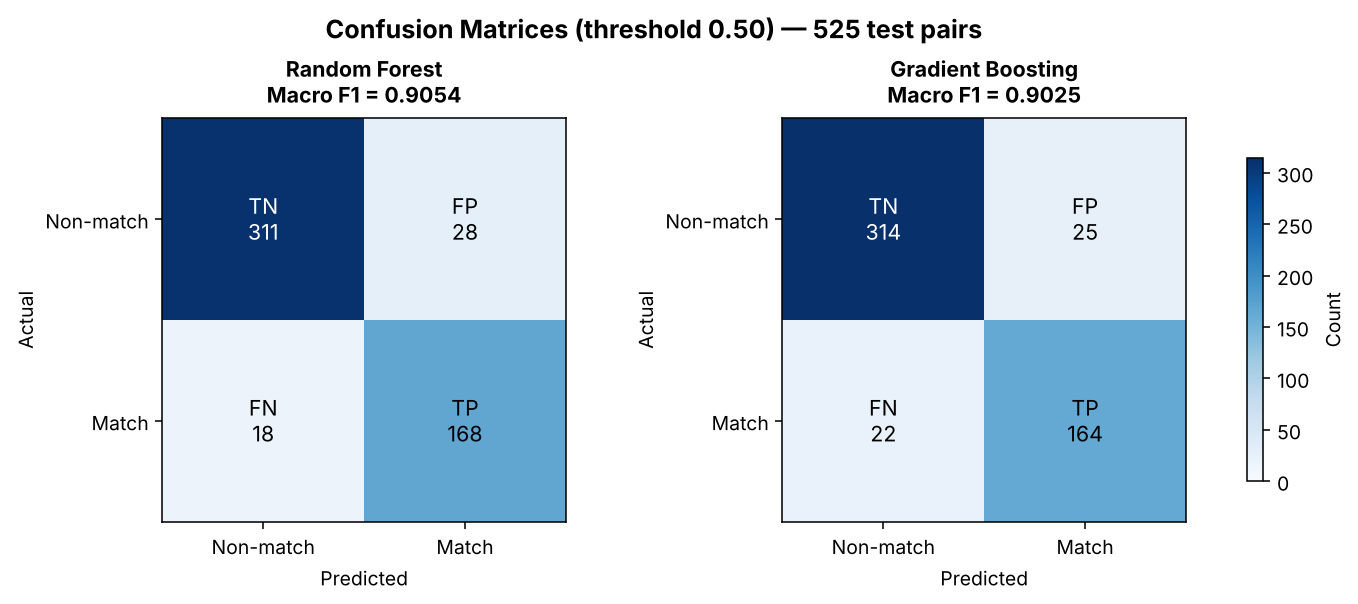

Cells show TP / FP / FN / TN


model                 Gradient Boosting Random Forest
group       value                                    
hard        Difficult       74/7/22/132  78/10/18/129
            Ordinary        90/18/0/182   90/18/0/182
source_pair dpd_ema           59/4/4/83     60/4/3/83
            dpd_fda          30/12/7/67    30/13/7/66
            ema_fda         75/9/11/164   78/11/8/162

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), dpi=140, layout='constrained')
cell_names = [['TN', 'FP'], ['FN', 'TP']]
cms = {k: confusion_matrix(y_test, tree_preds[k], labels=[0, 1]) for k in main_configs}
vmax = max(cm.max() for cm in cms.values())
for ax, (name, cm) in zip(axes, cms.items()):
    mf1 = f1_score(y_test, tree_preds[name], average='macro')
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=vmax)
    ax.set_title(f'{name.replace(" @0.50", "")}\nMacro F1 = {mf1:.4f}', fontsize=11, fontweight='bold', pad=8)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Non-match', 'Match'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Non-match', 'Match'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cell_names[i][j]}\n{cm[i, j]}', ha='center', va='center', fontsize=11,
                    color='white' if cm[i, j] > vmax * 0.6 else 'black')
fig.colorbar(im, ax=axes, shrink=0.8, label='Count')
fig.suptitle(f'Confusion Matrices (threshold 0.50) — {len(test)} test pairs', fontsize=13, fontweight='bold')
plt.savefig(fig_dir / 'ml_tree_classifier_confusion_matrices.png', bbox_inches='tight')
plt.show()

# Per-subgroup confusion matrices for every configuration
cm_rows = []
for k in main_configs:
    for col in ['hard', 'source_pair']:
        for val, g in test.groupby(col):
            tn, fp, fn, tp = confusion_matrix(g['match'], tree_preds[k][g.index], labels=[0, 1]).ravel()
            cm_rows.append({'model': k.replace(' @0.50', ''), 'group': col,
                            'value': {0: 'Ordinary', 1: 'Difficult'}.get(val, val),
                            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn})
cm_df = pd.DataFrame(cm_rows)
cm_df['cell'] = cm_df.apply(lambda r: f"{r.TP}/{r.FP}/{r.FN}/{r.TN}", axis=1)
print('Cells show TP / FP / FN / TN')
display(cm_df.pivot(index=['group', 'value'], columns='model', values='cell'))

### 6.3 Macro F1 by subgroup

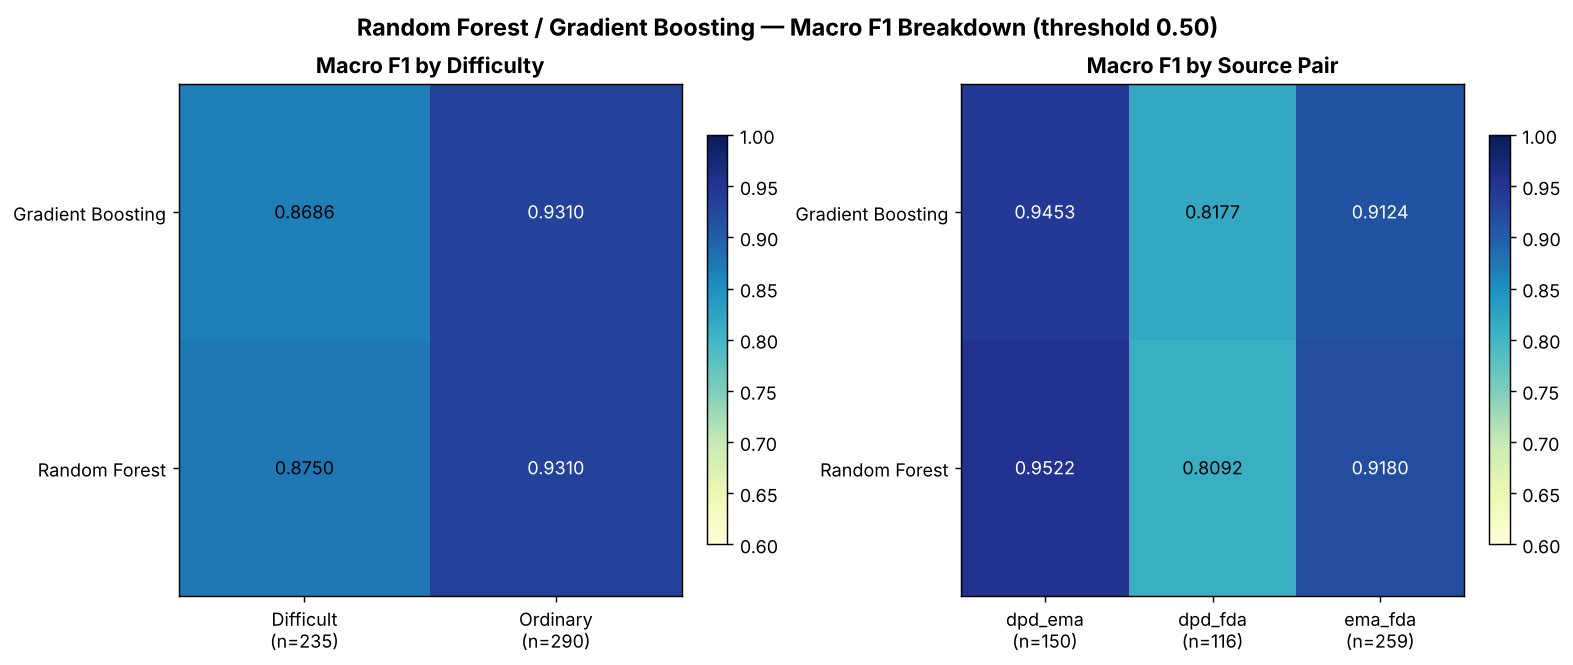

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=130, layout='constrained')
for ax, col, title in zip(axes, ['hard', 'source_pair'], ['Difficulty', 'Source Pair']):
    sub = breakdown_all[breakdown_all['group'] == col].copy()
    pivot = sub.pivot(index='model', columns='value', values='macro_f1')
    im = ax.imshow(pivot.values, cmap='YlGnBu', vmin=0.6, vmax=1, aspect='auto')
    counts = sub.groupby('value')['n'].first()
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([f'{v}\n(n={counts.get(v, "?")})' for v in pivot.columns])
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
    ax.set_title(f'Macro F1 by {title}', fontsize=12, fontweight='bold')
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            ax.text(j, i, f'{v:.4f}', ha='center', va='center', fontsize=10, color='white' if v > 0.9 else 'black')
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle('Random Forest / Gradient Boosting — Macro F1 Breakdown (threshold 0.50)', fontsize=13, fontweight='bold')
plt.savefig(fig_dir / 'ml_tree_classifier_group_macro_f1.png', bbox_inches='tight')
plt.show()

### 6.4 Feature importance

Impurity-based importance of the two final models, next to the absolute standardised coefficients of the Logistic Regression baseline.

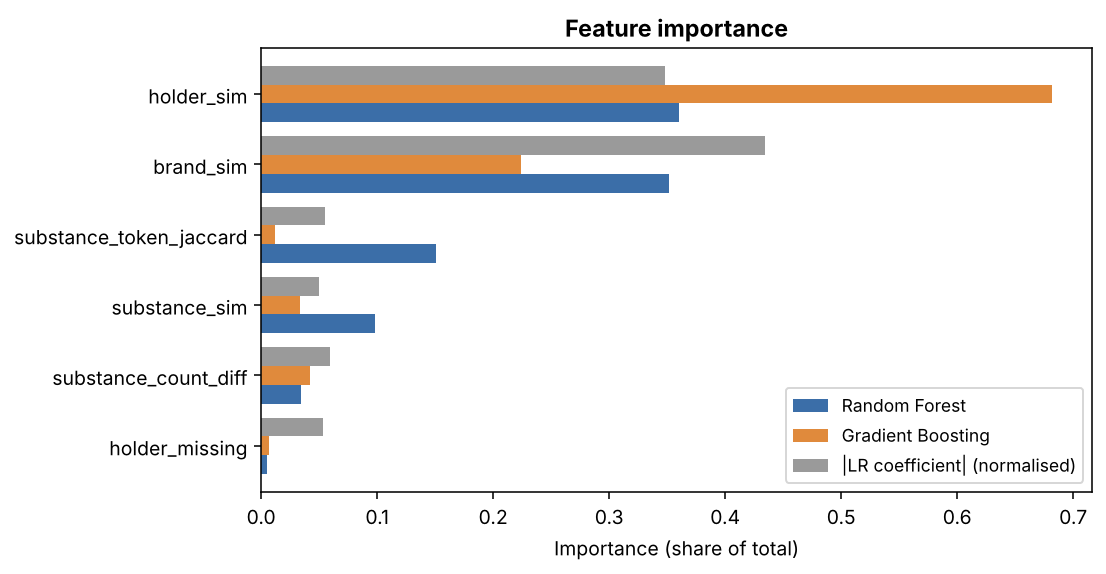

,Random Forest,Gradient Boosting,|LR coefficient| (normalised)
holder_sim,0.3600,0.6821,0.3484
brand_sim,0.3515,0.2240,0.4345
substance_token_jaccard,0.1507,0.0123,0.0548
substance_sim,0.0986,0.0331,0.0498
substance_count_diff,0.0339,0.0418,0.0592
holder_missing,0.0053,0.0067,0.0532


In [11]:
lr_coef = np.abs(lr.named_steps['clf'].coef_[0])
imp_df = pd.DataFrame({
    'Random Forest': searches['Random Forest'].final_model_.feature_importances_,
    'Gradient Boosting': searches['Gradient Boosting'].final_model_.feature_importances_,
    '|LR coefficient| (normalised)': lr_coef / lr_coef.sum(),
}, index=FEATURE_NAMES).sort_values('Random Forest')

fig, ax = plt.subplots(figsize=(8, 4.2), dpi=140)
imp_df.plot.barh(ax=ax, color=['#3b6ea8', '#e08a3c', '#9a9a9a'], width=0.8)
ax.set_xlabel('Importance (share of total)')
ax.set_title('Feature importance', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(fig_dir / 'ml_tree_classifier_feature_importance.png', bbox_inches='tight')
plt.show()
display(imp_df.sort_values('Random Forest', ascending=False).round(4))

## 7. Comparison of all matchers on the test set

In [12]:
def summary_row(name, pred, thr=None):
    cm = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {
        'Matcher': name,
        'Threshold': thr,
        'Macro F1': f1_score(y_test, pred, average='macro'),
        'Balanced Macro F1': balanced_macro_f1(pred),
        'Match P': precision_score(y_test, pred, pos_label=1),
        'Match R': recall_score(y_test, pred, pos_label=1),
        'Match F1': f1_score(y_test, pred, pos_label=1),
        'Non-match F1': f1_score(y_test, pred, pos_label=0),
        'Accuracy': accuracy_score(y_test, pred),
        'TP': cm[3], 'FP': cm[1], 'FN': cm[2], 'TN': cm[0],
    }

rows = [summary_row(k, p) for k, p in ref_preds.items()]
for key in searches:
    rows.append(summary_row(key, tree_preds[f'{key} @0.50'], 0.50))
    if tuned_thr[key] != 0.50:
        rows.append(summary_row(key, tree_preds[f'{key} @{tuned_thr[key]:.2f}'], tuned_thr[key]))
summary = pd.DataFrame(rows).sort_values('Macro F1', ascending=False).reset_index(drop=True)
display(summary.round(4))

# Save metrics for the report
eval_dir.mkdir(parents=True, exist_ok=True)
summary.to_csv(eval_dir / 'ml_tree_test_metrics.csv', index=False)

,Matcher,Threshold,Macro F1,Balanced Macro F1,Match P,Match R,Match F1,Non-match F1,Accuracy,TP,FP,FN,TN
0,Zero-shot LLM,NaN,0.9485,0.9571,0.9128,0.9570,0.9344,0.9626,0.9524,178,17,8,322
1,DistilBERT (tuned),NaN,0.9215,0.9209,0.9357,0.8602,0.8964,0.9466,0.9295,160,11,26,328
2,Random Forest,0.48,0.9075,0.8967,0.8579,0.9086,0.8825,0.9325,0.9143,169,28,17,311
3,Random Forest,0.50,0.9054,0.8931,0.8571,0.9032,0.8796,0.9311,0.9124,168,28,18,311
4,Gradient Boosting,0.50,0.9025,0.8918,0.8677,0.8817,0.8747,0.9304,0.9105,164,25,22,314
5,Gradient Boosting,0.44,0.9025,0.8918,0.8677,0.8817,0.8747,0.9304,0.9105,164,25,22,314
6,SVM,NaN,0.8698,0.8572,0.9379,0.7312,0.8218,0.9179,0.8876,136,9,50,330
7,Logistic Regression,NaN,0.8610,0.8587,0.9241,0.7204,0.8097,0.9124,0.8800,134,11,52,328
8,Exact-match baseline,NaN,0.7307,0.7251,0.8333,0.4839,0.6122,0.8492,0.7829,90,18,96,321


## 8. Error analysis

Errors of the configuration with the best **CV** score (chosen on train/val, not on test). For each error we flag whether SVM, DistilBERT and the LLM got the same pair wrong. Pairs that every matcher misses are candidates for gold-standard label noise.

In [13]:
best_key = hpo_df['cv_macro_f1'].idxmax()
best_pred = tree_preds[f'{best_key} @0.50']
print(f'Best configuration by CV macro F1: {best_key} '
      f'(CV {hpo_df.loc[best_key, "cv_macro_f1"]:.4f}, test {f1_score(y_test, best_pred, average="macro"):.4f})')

err = test.loc[best_pred != y_test, ['pair_id', 'source_pair', 'hard', 'match',
                                    'brandName1', 'brandName2', 'activeSubstances1', 'activeSubstances2',
                                    'licenceHolder1', 'licenceHolder2']].copy()
err['proba'] = test_proba[best_key][err.index].round(3)
err['type'] = np.where(err['match'] == 1, 'FN', 'FP')
for ref in ['SVM', 'DistilBERT (tuned)', 'Zero-shot LLM']:
    if ref in ref_preds:
        err[f'{ref} wrong'] = ref_preds[ref][err.index] != y_test[err.index]
print(err['type'].value_counts().to_string())

ref_cols = [c for c in err.columns if c.endswith(' wrong')]
err['all_wrong'] = err[ref_cols].all(axis=1)
print(f'\nErrors shared with every reference matcher: {err["all_wrong"].sum()} of {len(err)}')
print('Shared rows:', sorted(err.index[err['all_wrong']].tolist()))

# Pairs fixed relative to SVM
fixed = (ref_preds['SVM'] != y_test) & (best_pred == y_test)
broken = (ref_preds['SVM'] == y_test) & (best_pred != y_test)
print(f'Compared with SVM: {fixed.sum()} SVM errors fixed, {broken.sum()} new errors')

pd.set_option('display.max_colwidth', 45)
display(err.sort_values(['type', 'all_wrong'], ascending=[True, False]))

Best configuration by CV macro F1: Random Forest (CV 0.9023, test 0.9054)
type
FP    28
FN    18

Errors shared with every reference matcher: 8 of 46
Shared rows: [28, 162, 187, 220, 254, 302, 354, 509]
Compared with SVM: 32 SVM errors fixed, 19 new errors


,pair_id,source_pair,hard,match,brandName1,brandName2,activeSubstances1,activeSubstances2,licenceHolder1,licenceHolder2,proba,type,SVM wrong,DistilBERT (tuned) wrong,Zero-shot LLM wrong,all_wrong
162,DPD_AURO LAMIVUDINE ZIDOVUDINE|LAMIVUDINE...,dpd_fda,1,1,AURO-LAMIVUDINE/ZIDOVUDINE,LAMIVUDINE; ZIDOVUDINE,LAMIVUDINE; ZIDOVUDINE,EFAVIRENZ; LAMIVUDINE; ZIDOVUDINE,AURO PHARMA INC,AUROBINDO PHARMA LTD,0.190,FN,True,True,True,True
187,EMA_EMEA/H/C/002318 <-> FDA_REPAGLINIDE|R...,ema_fda,1,1,Repaglinide Accord,REPAGLINIDE,repaglinide,REPAGLINIDE,Accord Healthcare S.L.U.,AUROBINDO PHARMA LTD,0.235,FN,True,True,True,True
254,EMA_EMEA/H/C/000743 <-> FDA_EMEND|APREPITANT,ema_fda,1,1,Ivemend,EMEND,fosaprepitant,APREPITANT,Merck Sharp & Dohme B.V.,MSD,0.128,FN,True,True,True,True
302,EMA_EMEA/H/C/003958 <-> FDA_PEMETREXED|PE...,ema_fda,1,1,Pemetrexed Krka,PEMETREXED,pemetrexed disodium,PEMETREXED DISODIUM,KRKA d.d.,SHILPA,0.239,FN,True,True,True,True
354,EMA_EMEA/H/C/004666 <-> FDA_TADALAFIL|TAD...,ema_fda,1,1,Tadalafil Lilly,TADALAFIL,tadalafil,TADALAFIL,Eli Lilly Nederland B.V.,RISING,0.234,FN,True,True,True,True
42,DPD_DYANAVEL XR|AMPHETAMINE <-> FDA_DYANA...,dpd_fda,1,1,DYANAVEL XR,DYANAVEL XR 5,AMPHETAMINE,AMPHETAMINE; AMPHETAMINE ASPARTATE DEXTRO...,KYE PHARMACEUTICALS INC.,TRIS PHARMA INC,0.496,FN,True,False,False,False
56,DPD_NORINYL 1 50 28 TAB|MESTRANOL; NORETH...,dpd_fda,1,1,NORINYL 1/50 28 TAB,NORINYL 1+50 28-DAY,MESTRANOL; NORETHINDRONE,MESTRANOL; NORETHINDRONE,SYNTEX INC.,ACTAVIS LABS UT INC,0.242,FN,True,False,False,False
81,EMA_EMEA/H/C/004416 <-> FDA_ALKINDI SPRIN...,ema_fda,1,1,Alkindi,ALKINDI SPRINKLE,hydrocortisone,HYDROCORTISONE,Immedica Pharma AB,ETON,0.389,FN,True,True,False,False
83,EMA_EMEA/H/C/000278 <-> FDA_HERCEPTIN HYL...,ema_fda,1,1,Herceptin,HERCEPTIN HYLECTA,trastuzumab,TRASTUZUMAB AND HYALURONIDASE OYSK,Roche Registration GmbH,GENENTECH INC,0.039,FN,True,False,True,False
107,DPD_RHEUMOCAM INJECTION|MELOXICAM <-> EMA...,dpd_ema,1,1,RHEUMOCAM INJECTION,Rheumocam,MELOXICAM,meloxicam,CHANELLE PHARMACEUTICALS MANUFACTURING LI...,NaN,0.480,FN,True,True,False,False


## 9. Save predictions and settings

In [14]:
out = test[['pair_id', 'id1', 'id2', 'source_pair', 'hard', 'match']].copy()
for key in searches:
    tag = {'Random Forest': 'rf', 'Gradient Boosting': 'gb'}[key]
    out[f'proba_{tag}'] = test_proba[key].round(5)
    out[f'pred_{tag}'] = tree_preds[f'{key} @0.50']
    out[f'pred_{tag}_tuned'] = tree_preds[f'{key} @{tuned_thr[key]:.2f}']
out.to_csv(eval_dir / 'ml_tree_test_predictions.csv', index=False)

settings = {
    key: {
        'best_params': hpo_df.loc[key, 'best_params'],
        'cv_macro_f1': round(float(hpo_df.loc[key, 'cv_macro_f1']), 4),
        'tuned_threshold': tuned_thr[key],
        'features': FEATURE_NAMES,
    } for key in searches
}
settings['_cv'] = 'StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring=f1_macro, RandomizedSearchCV n_iter=%d' % N_ITER
with open(eval_dir / 'ml_tree_best_settings.json', 'w') as f:
    json.dump(settings, f, indent=2, default=str)

display(pd.DataFrame(timing_rows).set_index('config').round(3))
print('Saved:', 'ml_tree_test_predictions.csv, ml_tree_test_metrics.csv, ml_tree_best_settings.json')

,fit_s,predict_525_s
config,,
Random Forest,0.687,0.022
Gradient Boosting,0.310,0.002


Saved: ml_tree_test_predictions.csv, ml_tree_test_metrics.csv, ml_tree_best_settings.json


## 10. Conclusion

**1. Trees beat SVM and LR on the same features.** On the six shared features, Random Forest reaches **0.9054** test Macro F1 and Gradient Boosting **0.9025**, against **0.8698** (SVM) and **0.8610** (LR). Random Forest has the best CV score (0.9023) and is the recommended ML matcher.

**2. The gain comes from recall.** SVM and LR draw a conservative boundary (match recall 0.72–0.73, 50–52 missed matches). The trees find 164–168 of 186 matches (recall 0.88–0.90) and miss no match in the ordinary pool, at the cost of more false positives (25–28 vs 9–11). Non-linear models can combine the signals, for example *similar brand and substance but a different holder*, which a single linear boundary cannot.

**3. Subgroups.** On the hard pool, RF reaches 0.8750 Macro F1 (SVM 0.8349, LR 0.8166). DPD/FDA stays the weakest source pair for every ML model (RF 0.8092, GB 0.8177, SVM 0.7887), mainly because of false positives (match precision about 0.70).

**4. What drives the decision.** Brand similarity and licence-holder similarity dominate in all three models (tree importances and the standardised LR coefficients, 2.03 and 1.63). The substance features correlate strongly with brand similarity (r ≈ 0.85) and add little on top.

**5. Typical errors.** Most false positives are pairs with the same substance and a similar or identical brand from different licence holders: competing generics, and same-brand products sold by a different company in another jurisdiction (which the gold standard labels both ways). Holder similarity is only partly informative here, because generic words such as *PHARMA* are shared across unrelated companies.

**6. Threshold tuning does not help.** The out-of-fold gain is at most 0.005, below the CV standard deviation (about 0.01), so the default 0.50 is kept.

**7. Position among all matchers.** The tree models rank above SVM/LR but below DistilBERT (0.9215) and the zero-shot LLM (0.9485). 8 of the 46 RF errors are shared with SVM, DistilBERT and the LLM, including the four pairs the LLM report flags as likely gold-standard label noise (rows 162, 187, 302, 354).

**8. Cost.** Training takes under one second and scoring 525 pairs about 0.02 seconds, so the model can score all blocking candidates locally without API cost.